# 02 — Modelado: comparación de modelos clásicos y de ensemble

Clasificación binaria (Normal vs. Patológico) de sonidos cardíacos (HS) y
pulmonares (LS) sobre la matriz de features del EDA.

Principios de diseño (críticos con n pequeño):
 - TODO el preprocesamiento (escalado + balanceo) va DENTRO de un Pipeline que
   se ajusta solo con el fold de entrenamiento -> sin data leakage.
 - Validación cruzada estratificada REPETIDA -> media + desvío (intervalos).
 - Métricas clínicas: sensibilidad, especificidad, F1-macro, AUC.
 - Se comparan modelos individuales y de ensemble, más un MLP chico.
 - Las DOS estrategias de balanceo (SMOTE y class_weight) se evalúan y se
   guardan en la misma corrida, en un único CSV con la columna `balanceo`.

In [19]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import recall_score, make_scorer, confusion_matrix

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Modelos de boosting (opcionales: si no están instalados, se omiten)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

In [20]:
# ---------- Configuración ----------
FEAT_DIR = Path("../outputs")          # dónde quedaron hs_features.csv / ls_features.csv
OUT_DIR = Path("../outputs"); OUT_DIR.mkdir(exist_ok=True)
BALANCE_MODES = ["smote", "class_weight"]   # ambas estrategias en una sola corrida
N_SPLITS, N_REPEATS = 5, 10            # 5-fold x 10 repeticiones = 50 evaluaciones
DROP_COLS = ["file_id", "label", "label_binary"]  # columnas que no son features
TARGET = "label_binary"               # 0 = Normal, 1 = Patológico

In [21]:
def load_xy(csv_name):
    """Carga un CSV de features y devuelve X (features) e y (etiqueta binaria)."""
    path = FEAT_DIR / csv_name
    if not path.exists():                       # fallback a ../data por si acaso
        path = Path("../data") / csv_name
    df = pd.read_csv(path)
    y = df[TARGET].astype(int).values
    X = df.drop(columns=[c for c in DROP_COLS if c in df.columns])
    X = X.select_dtypes(include=[np.number])    # solo numéricas
    return X.values, y, list(X.columns)

In [22]:
def make_pipeline(estimator, balance, force_smote=False):
    """Arma un Pipeline: escalado -> (SMOTE opcional) -> modelo.
    El escalado y el SMOTE se ajustan SOLO con el train de cada fold.
    """
    steps = [("scaler", StandardScaler())]
    if balance == "smote" or force_smote:
        # k_neighbors chico: la clase minoritaria en cada fold de train es muy pequeña
        steps.append(("smote", SMOTE(k_neighbors=3, random_state=RANDOM_STATE)))
    steps.append(("clf", estimator))
    return ImbPipeline(steps)


def build_models(balance):
    """Devuelve un dict {nombre: pipeline} para la estrategia de balanceo dada.
    Bajo 'class_weight' los modelos que lo soportan usan class_weight='balanced';
    el MLP no lo soporta, así que en ese modo se balancea con SMOTE (excepción
    documentada).
    """
    cw = "balanced" if balance == "class_weight" else None
    models = {}
    models["LogReg"] = make_pipeline(
        LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE), balance)
    models["SVM-Linear"] = make_pipeline(
        SVC(kernel="linear", probability=True, class_weight=cw, random_state=RANDOM_STATE), balance)
    models["SVM-RBF"] = make_pipeline(
        SVC(kernel="rbf", probability=True, class_weight=cw, random_state=RANDOM_STATE), balance)
    models["DecisionTree"] = make_pipeline(
        DecisionTreeClassifier(class_weight=cw, max_depth=4, random_state=RANDOM_STATE), balance)
    models["RandomForest"] = make_pipeline(
        RandomForestClassifier(n_estimators=300, class_weight=cw, max_depth=None,
                               random_state=RANDOM_STATE), balance)
    if HAS_XGB:
        models["XGBoost"] = make_pipeline(
            XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                          subsample=0.9, eval_metric="logloss", random_state=RANDOM_STATE), balance)
    if HAS_LGBM:
        models["LightGBM"] = make_pipeline(
            LGBMClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                           class_weight=cw, random_state=RANDOM_STATE, verbose=-1), balance)
    # Ensemble por votación (soft): combina 3 modelos diversos
    voting = VotingClassifier(estimators=[
        ("lr", LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE)),
        ("rf", RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=RANDOM_STATE)),
        ("svm", SVC(kernel="rbf", probability=True, class_weight=cw, random_state=RANDOM_STATE)),
    ], voting="soft")
    models["Voting"] = make_pipeline(voting, balance)
    # MLP chico (perceptrón multicapa) sobre la matriz tabular.
    # No soporta class_weight -> en modo class_weight se balancea con SMOTE.
    models["MLP"] = make_pipeline(
        MLPClassifier(hidden_layer_sizes=(16,), alpha=1e-2, early_stopping=True,
                      max_iter=1000, random_state=RANDOM_STATE),
        balance, force_smote=(balance == "class_weight"))
    return models

In [23]:
# Métricas: sensibilidad = recall clase 1 (patológico); especificidad = recall clase 0 (normal)
SCORERS = {
    "sensibilidad": make_scorer(recall_score, pos_label=1, zero_division=0),
    "especificidad": make_scorer(recall_score, pos_label=0, zero_division=0),
    "f1_macro": "f1_macro",
    "AUC": "roc_auc",
    "balanced_acc": "balanced_accuracy",
}


def evaluate(X, y, balance, label=""):
    """Evalúa todos los modelos con CV estratificada repetida, para UNA estrategia
    de balanceo. Devuelve un DataFrame con media +/- desvío por métrica.
    """
    cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
    rows = []
    for name, pipe in build_models(balance).items():
        res = cross_validate(pipe, X, y, cv=cv, scoring=SCORERS, n_jobs=-1, error_score="raise")
        row = {"balanceo": balance, "modelo": name}
        for m in SCORERS:
            vals = res[f"test_{m}"]
            row[m] = f"{np.mean(vals):.3f} ± {np.std(vals):.3f}"
            row[f"_{m}_mean"] = np.mean(vals)   # numérico para ordenar
        rows.append(row)
    df = pd.DataFrame(rows).sort_values("_AUC_mean", ascending=False).reset_index(drop=True)
    show = ["modelo"] + list(SCORERS.keys())
    print(f"\n===== {label} (balanceo={balance}, {N_SPLITS}x{N_REPEATS} CV) =====")
    print(df[show].to_string(index=False))
    return df


def evaluate_all(X, y, label=""):
    """Corre la evaluación para las dos estrategias de balanceo y las apila."""
    return pd.concat([evaluate(X, y, b, label) for b in BALANCE_MODES], ignore_index=True)


def confusion_for_best(X, y, best_name, balance, label=""):
    """Matriz de confusión agregada (out-of-fold) del mejor modelo."""
    pipe = build_models(balance)[best_name]
    cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    y_pred = cross_val_predict(pipe, X, y, cv=cv, n_jobs=-1)
    cm = confusion_matrix(y, y_pred)
    print(f"\nMatriz de confusión OOF — {label} — {best_name} (balanceo={balance})")
    print(pd.DataFrame(cm, index=["real:Normal", "real:Patol"],
                       columns=["pred:Normal", "pred:Patol"]).to_string())
    return cm


def save_results(df, csv_name):
    """Guarda el DataFrame de resultados (ambos balanceos) sin las columnas auxiliares."""
    out = df.drop(columns=[c for c in df.columns if c.startswith("_")])
    out.to_csv(OUT_DIR / csv_name, index=False)
    return out


def best_per_balance(df):
    """Mejor modelo por AUC para cada estrategia de balanceo -> {balanceo: modelo}."""
    idx = df.groupby("balanceo")["_AUC_mean"].idxmax()
    return dict(zip(df.loc[idx, "balanceo"], df.loc[idx, "modelo"]))

In [24]:
# ---------- Ejecución: Sonidos cardíacos (HS) ----------
X_hs, y_hs, feat_names = load_xy("hs_features.csv")
print(f"HS: X={X_hs.shape}, positivos(patológico)={int(y_hs.sum())}, negativos(normal)={int((y_hs==0).sum())}")
res_hs = evaluate_all(X_hs, y_hs, label="Sonidos cardíacos (HS)")
best_hs = best_per_balance(res_hs)
for b, m in best_hs.items():
    confusion_for_best(X_hs, y_hs, m, b, label="HS")
save_results(res_hs, "results_hs.csv")

HS: X=(50, 105), positivos(patológico)=41, negativos(normal)=9

===== Sonidos cardíacos (HS) (balanceo=smote, 5x10 CV) =====
      modelo  sensibilidad especificidad      f1_macro           AUC  balanced_acc
RandomForest 0.906 ± 0.107 0.470 ± 0.405 0.652 ± 0.178 0.824 ± 0.174 0.688 ± 0.182
    LightGBM 0.884 ± 0.130 0.510 ± 0.394 0.661 ± 0.176 0.789 ± 0.210 0.697 ± 0.178
      Voting 0.930 ± 0.088 0.410 ± 0.356 0.643 ± 0.159 0.783 ± 0.186 0.670 ± 0.157
     XGBoost 0.879 ± 0.126 0.480 ± 0.387 0.646 ± 0.170 0.780 ± 0.194 0.680 ± 0.178
     SVM-RBF 0.951 ± 0.073 0.240 ± 0.304 0.578 ± 0.167 0.748 ± 0.245 0.596 ± 0.147
      LogReg 0.864 ± 0.120 0.520 ± 0.412 0.641 ± 0.159 0.690 ± 0.252 0.692 ± 0.182
  SVM-Linear 0.837 ± 0.134 0.340 ± 0.367 0.555 ± 0.151 0.633 ± 0.246 0.589 ± 0.173
DecisionTree 0.864 ± 0.106 0.350 ± 0.377 0.580 ± 0.174 0.607 ± 0.182 0.607 ± 0.182
         MLP 0.388 ± 0.174 0.730 ± 0.335 0.421 ± 0.151 0.508 ± 0.202 0.559 ± 0.191

===== Sonidos cardíacos (HS) (balanceo=class

,balanceo,modelo,sensibilidad,especificidad,f1_macro,AUC,balanced_acc
0,smote,RandomForest,0.906 ± 0.107,0.470 ± 0.405,0.652 ± 0.178,0.824 ± 0.174,0.688 ± 0.182
1,smote,LightGBM,0.884 ± 0.130,0.510 ± 0.394,0.661 ± 0.176,0.789 ± 0.210,0.697 ± 0.178
2,smote,Voting,0.930 ± 0.088,0.410 ± 0.356,0.643 ± 0.159,0.783 ± 0.186,0.670 ± 0.157
3,smote,XGBoost,0.879 ± 0.126,0.480 ± 0.387,0.646 ± 0.170,0.780 ± 0.194,0.680 ± 0.178
4,smote,SVM-RBF,0.951 ± 0.073,0.240 ± 0.304,0.578 ± 0.167,0.748 ± 0.245,0.596 ± 0.147
5,smote,LogReg,0.864 ± 0.120,0.520 ± 0.412,0.641 ± 0.159,0.690 ± 0.252,0.692 ± 0.182
6,smote,SVM-Linear,0.837 ± 0.134,0.340 ± 0.367,0.555 ± 0.151,0.633 ± 0.246,0.589 ± 0.173
7,smote,DecisionTree,0.864 ± 0.106,0.350 ± 0.377,0.580 ± 0.174,0.607 ± 0.182,0.607 ± 0.182
8,smote,MLP,0.388 ± 0.174,0.730 ± 0.335,0.421 ± 0.151,0.508 ± 0.202,0.559 ± 0.191
9,class_weight,RandomForest,0.983 ± 0.043,0.110 ± 0.230,0.514 ± 0.136,0.839 ± 0.157,0.546 ± 0.111


In [25]:
# ---------- Ejecución: Sonidos pulmonares (LS) ----------
X_ls, y_ls, _ = load_xy("ls_features.csv")
print(f"LS: X={X_ls.shape}, positivos(patológico)={int(y_ls.sum())}, negativos(normal)={int((y_ls==0).sum())}")
res_ls = evaluate_all(X_ls, y_ls, label="Sonidos pulmonares (LS)")
best_ls = best_per_balance(res_ls)
for b, m in best_ls.items():
    confusion_for_best(X_ls, y_ls, m, b, label="LS")
save_results(res_ls, "results_ls.csv")

LS: X=(50, 105), positivos(patológico)=38, negativos(normal)=12

===== Sonidos pulmonares (LS) (balanceo=smote, 5x10 CV) =====
      modelo  sensibilidad especificidad      f1_macro           AUC  balanced_acc
      LogReg 0.992 ± 0.031 0.930 ± 0.164 0.965 ± 0.078 0.998 ± 0.011 0.961 ± 0.088
  SVM-Linear 0.982 ± 0.044 0.913 ± 0.177 0.948 ± 0.079 0.997 ± 0.014 0.948 ± 0.090
      Voting 0.998 ± 0.017 0.753 ± 0.259 0.895 ± 0.119 0.995 ± 0.016 0.875 ± 0.131
     SVM-RBF 0.988 ± 0.037 0.673 ± 0.311 0.841 ± 0.151 0.981 ± 0.037 0.830 ± 0.152
RandomForest 0.974 ± 0.057 0.713 ± 0.277 0.853 ± 0.124 0.965 ± 0.053 0.844 ± 0.130
    LightGBM 0.959 ± 0.070 0.750 ± 0.243 0.861 ± 0.118 0.948 ± 0.066 0.854 ± 0.127
     XGBoost 0.927 ± 0.087 0.730 ± 0.251 0.824 ± 0.103 0.925 ± 0.086 0.829 ± 0.117
DecisionTree 0.886 ± 0.118 0.743 ± 0.277 0.791 ± 0.139 0.815 ± 0.135 0.815 ± 0.135
         MLP 0.532 ± 0.199 0.913 ± 0.189 0.608 ± 0.171 0.776 ± 0.177 0.723 ± 0.160

===== Sonidos pulmonares (LS) (balanceo=cl

,balanceo,modelo,sensibilidad,especificidad,f1_macro,AUC,balanced_acc
0,smote,LogReg,0.992 ± 0.031,0.930 ± 0.164,0.965 ± 0.078,0.998 ± 0.011,0.961 ± 0.088
1,smote,SVM-Linear,0.982 ± 0.044,0.913 ± 0.177,0.948 ± 0.079,0.997 ± 0.014,0.948 ± 0.090
2,smote,Voting,0.998 ± 0.017,0.753 ± 0.259,0.895 ± 0.119,0.995 ± 0.016,0.875 ± 0.131
3,smote,SVM-RBF,0.988 ± 0.037,0.673 ± 0.311,0.841 ± 0.151,0.981 ± 0.037,0.830 ± 0.152
4,smote,RandomForest,0.974 ± 0.057,0.713 ± 0.277,0.853 ± 0.124,0.965 ± 0.053,0.844 ± 0.130
5,smote,LightGBM,0.959 ± 0.070,0.750 ± 0.243,0.861 ± 0.118,0.948 ± 0.066,0.854 ± 0.127
6,smote,XGBoost,0.927 ± 0.087,0.730 ± 0.251,0.824 ± 0.103,0.925 ± 0.086,0.829 ± 0.117
7,smote,DecisionTree,0.886 ± 0.118,0.743 ± 0.277,0.791 ± 0.139,0.815 ± 0.135,0.815 ± 0.135
8,smote,MLP,0.532 ± 0.199,0.913 ± 0.189,0.608 ± 0.171,0.776 ± 0.177,0.723 ± 0.160
9,class_weight,LogReg,0.990 ± 0.043,0.937 ± 0.159,0.966 ± 0.081,0.998 ± 0.011,0.963 ± 0.087



===== HS — LOOCV, ROC agrupada (n=50) =====
    balanceo       modelo  AUC_pooled  AP_pooled
       smote RandomForest    0.836043   0.961630
class_weight RandomForest    0.815718   0.956314
class_weight      XGBoost    0.807588   0.948489
       smote       Voting    0.780488   0.946430
       smote      XGBoost    0.758808   0.935545
class_weight       Voting    0.742547   0.923378
       smote     LightGBM    0.728997   0.905438
class_weight     LightGBM    0.720867   0.914922
class_weight      SVM-RBF    0.704607   0.873334
class_weight       LogReg    0.693767   0.873922
       smote       LogReg    0.685637   0.870769
class_weight DecisionTree    0.685637   0.879058
       smote      SVM-RBF    0.666667   0.861337
       smote DecisionTree    0.661247   0.870970
       smote   SVM-Linear    0.555556   0.830778
       smote          MLP    0.520325   0.867563
class_weight          MLP    0.520325   0.867563
class_weight   SVM-Linear    0.509485   0.819284


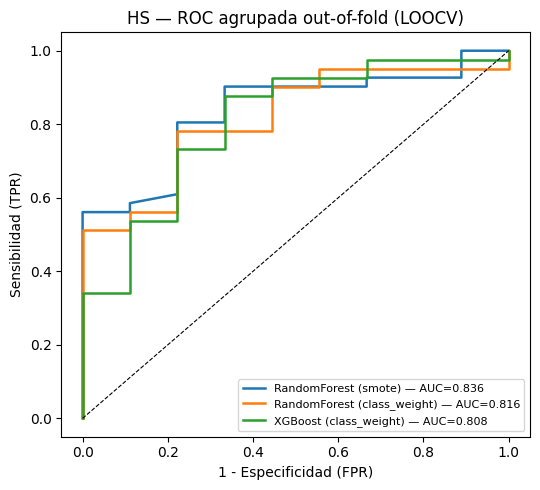

In [26]:
# ---------- LOOCV + ROC agrupada (pooled) — HS ----------
# Con solo 9 casos normales, la especificidad por fold es muy inestable (cada fold
# de test tiene 1-2 normales). LOOCV deja UNA muestra afuera por vez y se juntan
# TODAS las probabilidades out-of-fold en una única curva ROC (pooled): una
# estimación de AUC con menos varianza de partición que el promedio por fold.
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score


def loocv_probas(X, y, balance):
    """Probabilidad out-of-fold (LOOCV) de la clase patológica, por modelo."""
    loo = LeaveOneOut()
    return pd.DataFrame({
        name: cross_val_predict(pipe, X, y, cv=loo, method="predict_proba", n_jobs=-1)[:, 1]
        for name, pipe in build_models(balance).items()
    })


rows, probas = [], {}
for b in BALANCE_MODES:
    P = loocv_probas(X_hs, y_hs, b)
    for name in P.columns:
        probas[f"{b}|{name}"] = P[name].values
        rows.append({"balanceo": b, "modelo": name,
                     "AUC_pooled": roc_auc_score(y_hs, P[name]),
                     "AP_pooled": average_precision_score(y_hs, P[name])})

loocv_hs = pd.DataFrame(rows).sort_values("AUC_pooled", ascending=False).reset_index(drop=True)
print(f"\n===== HS — LOOCV, ROC agrupada (n={len(y_hs)}) =====")
print(loocv_hs.to_string(index=False))
loocv_hs.to_csv(OUT_DIR / "results_hs_loocv.csv", index=False)
pd.DataFrame(probas).assign(y_true=y_hs).to_csv(OUT_DIR / "hs_loocv_probas.csv", index=False)

# Curvas ROC agrupadas de los 3 mejores (modelo + estrategia de balanceo)
fig, ax = plt.subplots(figsize=(5.5, 5))
for _, r in loocv_hs.head(3).iterrows():
    fpr, tpr, _ = roc_curve(y_hs, probas[f"{r.balanceo}|{r.modelo}"])
    ax.plot(fpr, tpr, lw=1.8, label=f"{r.modelo} ({r.balanceo}) — AUC={r.AUC_pooled:.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set(xlabel="1 - Especificidad (FPR)", ylabel="Sensibilidad (TPR)",
       title="HS — ROC agrupada out-of-fold (LOOCV)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "15_roc_loocv_hs.png", dpi=150)

In [27]:
# ---------- Importancia de features (interpretación, no es estimación de desempeño) ----------
def top_importances(X, y, feat_names, k=15):
    rf = RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=RANDOM_STATE)
    rf.fit(StandardScaler().fit_transform(X), y)
    imp = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False)
    return imp.head(k)

print("\nTop 15 features (HS) por importancia RF:")
print(top_importances(X_hs, y_hs, feat_names).to_string())


Top 15 features (HS) por importancia RF:
mfcc_7_mean                 0.057565
mfcc_6_mean                 0.050118
spectral_contrast_2_std     0.049848
mfcc_5_max                  0.044532
spectral_contrast_4_mean    0.040676
mfcc_5_mean                 0.033955
spectral_rolloff_mean       0.030853
mfcc_4_max                  0.030268
mfcc_3_mean                 0.025298
mfcc_5_min                  0.020457
mfcc_4_std                  0.020277
zcr_mean                    0.017539
mfcc_13_mean                0.017010
spectral_centroid_mean      0.016236
spectral_centroid_std       0.015329


## Ajuste de hiperparámetros (patrón de CV anidada — opcional)

Con n pequeño, para elegir hiperparámetros SIN contaminar la estimación de
desempeño se usa validación cruzada anidada: un CV interno tunea y un CV
externo estima. Ejemplo para Random Forest (descomentar para usar):

```python
from sklearn.model_selection import GridSearchCV, cross_val_score
grid = {"clf__max_depth": [3, 5, None], "clf__n_estimators": [200, 400]}
inner = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
outer = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(make_pipeline(RandomForestClassifier(class_weight="balanced",
             random_state=RANDOM_STATE), "class_weight"), grid, cv=inner,
             scoring="roc_auc", n_jobs=-1)
nested_auc = cross_val_score(search, X_hs, y_hs, cv=outer, scoring="roc_auc")
print("AUC anidada:", nested_auc.mean(), "+/-", nested_auc.std())
```

In [28]:
from sklearn.model_selection import GridSearchCV, cross_val_score
grid = {"clf__max_depth": [3, 5, None], "clf__n_estimators": [200, 400]}
inner = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
outer = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(make_pipeline(RandomForestClassifier(class_weight="balanced",
             random_state=RANDOM_STATE), "class_weight"), grid, cv=inner, scoring="roc_auc", n_jobs=-1)
nested_auc = cross_val_score(search, X_hs, y_hs, cv=outer, scoring="roc_auc")
print("AUC anidada:", nested_auc.mean(), "+/-", nested_auc.std())

AUC anidada: 0.7930555555555555 +/- 0.10761872571005843
